# NBA shot quality

**Julian Calas**

How likely is a shot to go in, and how many points is it worth? Who makes more shots than that price, and who gets the best looks in the first place?

This notebook is the same pipeline as `scripts/run_pipeline.py`, told in order. The write-up for a hiring manager is `README.md`. The interview version of the ideas is `LEARNING_NOTES.md`.

The holdout is the 2025-26 regular season. Nothing in that season is used to pick the model.


## Setup

The package lives in `src/`. This cell finds the repo whether the notebook was launched from the root or from `notebooks/`.


In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
for candidate in [here, *here.parents]:
    if (candidate / "src" / "shotquality").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not find the shotquality package. Open the notebook from the repo.")

sys.path.insert(0, str(ROOT / "src"))

from shotquality.analysis.leaderboards import build_leaderboards
from shotquality.analysis.sql_queries import descriptive_bundle, player_aggregate
from shotquality.config import FIGURES, TEST_SEASON
from shotquality.data.clean import build_shot_table
from shotquality.data.database import build_database
from shotquality.data.pull import load_common_frame
from shotquality.features.build import FEATURE_COLUMNS, FORBIDDEN_COLUMNS, split_shots
from shotquality.models.train import train_models
from shotquality.viz.charts import (
    plot_calibration,
    plot_feature_importance,
    plot_model_comparison,
    plot_player_chart,
    plot_player_making,
    plot_selection_vs_making,
    plot_shot_density,
    plot_team_making,
    plot_value_by_distance,
    plot_xfg_heatmap,
    plot_xpts_heatmap,
    plot_zone_rates,
)

FIGURES.mkdir(parents=True, exist_ok=True)
print("Repo:", ROOT)


Repo: /workspace


## The shots

Three regular seasons. The loader reads the cached SportsDataverse files in `data/raw/` (the live NBA stats API timed out when this was built; `scripts/pull_shots.py` still tries that API first if you ask it to). Heaves stay in the table with a flag so they can be counted. The model drops them later.


In [2]:
common = load_common_frame(source="auto")
shots, quality = build_shot_table(common)

print(f"Rows in: {quality['rows_in']:,}")
print(f"Duplicate rows removed: {quality['dropped_duplicates']:,}")
print(f"Rows out: {quality['rows_out']:,}")
print(f"Heaves (40+ feet): {quality['heaves']:,}")
print(f"Source: {quality['data_source']}")
print()
for season in quality["seasons"]:
    print(
        f"{season['season']}: {season['shots']:,} shots, {season['games']} games, "
        f"FG% {season['fg_pct']:.1%}, heaves {season['heaves']}, full schedule {season['full_season_games']}"
    )


Rows in: 657,388
Duplicate rows removed: 24
Rows out: 657,364
Heaves (40+ feet): 1,187
Source: ['sportsdataverse']

2023-24: 218,689 shots, 1230 games, FG% 47.4%, heaves 510, full schedule True
2024-25: 219,519 shots, 1230 games, FG% 46.7%, heaves 621, full schedule True
2025-26: 219,156 shots, 1230 games, FG% 47.1%, heaves 56, full schedule True


## SQL: season, zone, action

DuckDB is the analysis database. Season totals and the zone profile are ordinary `GROUP BY`s. Heaves are out of the zone query. A 2% make rate from 60 feet is not a zone anyone chooses.


In [3]:
db_path = ROOT / "data" / "processed" / "shots.duckdb"
connection = build_database(shots, predictions=None, path=db_path)
bundle = descriptive_bundle(connection, TEST_SEASON)

seasons = bundle["seasons"].copy()
seasons["fg_pct"] = seasons["fg_pct"].map(lambda x: f"{x:.1%}")
seasons["three_rate"] = seasons["three_rate"].map(lambda x: f"{x:.1%}")
display(seasons)

zones = bundle["zones"].copy()
zones["fg_pct"] = zones["fg_pct"].map(lambda x: f"{x:.1%}")
zones["avg_distance_ft"] = zones["avg_distance_ft"].round(1)
zones["points_per_shot"] = zones["points_per_shot"].round(2)
display(zones)

actions = bundle["actions"].copy()
actions["fg_pct"] = actions["fg_pct"].map(lambda x: f"{x:.1%}")
actions["avg_distance_ft"] = actions["avg_distance_ft"].round(1)
display(actions)
connection.close()


,season,shots,games,players,fg_pct,three_rate,heaves
0,2023-24,218689,1230,568,47.4%,39.5%,510.0
1,2024-25,219519,1230,566,46.7%,42.1%,621.0
2,2025-26,219156,1230,582,47.1%,41.5%,56.0


,shot_zone_basic,fga,fg_pct,avg_distance_ft,avg_point_value,points_per_shot
0,Above the Break 3,198720,35.4%,26.3,3.0,1.06
1,Restricted Area,188172,66.6%,1.9,2.0,1.33
2,In The Paint (Non-RA),132695,44.3%,7.9,2.0,0.89
3,Mid-Range,66718,41.7%,15.8,2.0,0.83
4,Left Corner 3,36189,38.6%,23.3,3.0,1.16
5,Right Corner 3,33683,39.0%,23.4,3.0,1.17


,action_group,fga,fg_pct,avg_distance_ft
0,dunk,39872,88.6%,1.7
1,layup,161264,57.5%,2.9
2,tip,14234,48.5%,0.5
3,hook,18234,48.1%,6.0
4,floater,58140,44.9%,8.3
5,jumper,364433,38.3%,22.5


Restricted-area shots go in about two-thirds of the time and are worth about 1.33 points. A corner three goes in under 40% of the time and is still worth more than a midrange jumper or a non-restricted paint touch, because of the extra point. That is the whole reason to score shots in points instead of FG%.

The zone chart below is FG%. The point values are the last column of the table.


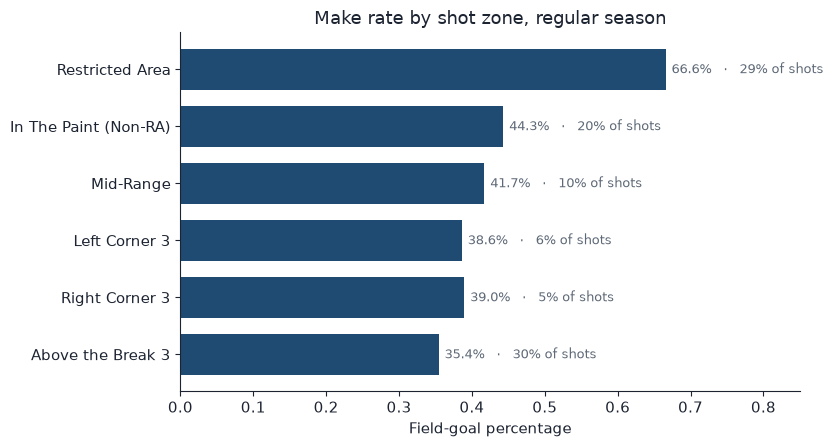

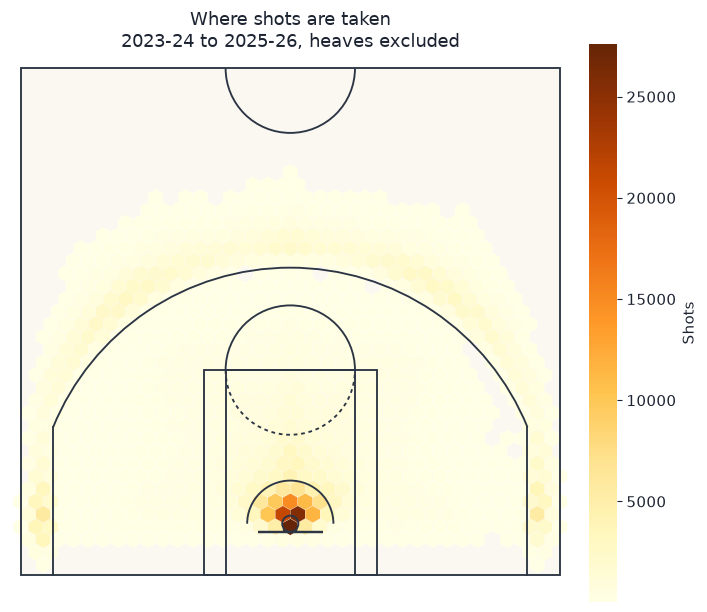

In [4]:
fig = plot_zone_rates(shots, FIGURES / "zone_make_rates.png")
display(fig)
plt.close(fig)

fig = plot_shot_density(shots, FIGURES / "shot_density.png")
display(fig)
plt.close(fig)


## Features the model is allowed to see

Location, distance, zone, a coarse action family, 2 vs 3, the game clock, and the period. The made/missed flag is the label. Player id is banned too: a model that knows who is shooting will bake that player into "expected" and points over expected will collapse toward zero.

Action strings are collapsed to dunk, layup, floater, tip, hook, and jumper. Step-backs stay inside jumper so a specialist's move is not relabeled as shot quality. Dunks in the table above go in around 90%. That is a property of the shot, known before it reaches the rim.


In [5]:
print("Features:")
for column in FEATURE_COLUMNS:
    print(" ", column)
print()
leaked = set(FEATURE_COLUMNS) & set(FORBIDDEN_COLUMNS)
print("Overlap with forbidden columns:", sorted(leaked) or "none")
print()
print(shots.loc[shots["is_heave"] == 0, "action_group"].value_counts().to_string())


Features:
  shot_distance
  loc_x_ft
  loc_y_ft
  seconds_left
  late_clock
  period
  shot_zone_basic
  shot_zone_range
  action_group
  shot_type

Overlap with forbidden columns: none

action_group
jumper     364433
layup      161264
floater     58140
dunk        39872
hook        18234
tip         14234


## Split by season

Fit and validation are 2023-24 and 2024-25. Validation is the last 20% of 2024-25 game ids, used only to stop boosting and to pick the model. The test set is every non-heave shot in 2025-26. Game ids follow the schedule (a postponement keeps its id), so the validation cut is not a perfect calendar. The test cut is a full later season, which is the one that matters.


In [6]:
modeled = shots.loc[shots["is_heave"] == 0].copy()
parts = split_shots(modeled)
for name in ("fit", "val", "train", "test"):
    part = parts[name]
    print(
        f"{name:5}  shots {len(part):,}   games {part['game_id'].nunique():,}   "
        f"seasons {sorted(part['season'].unique())}"
    )

assert set(parts["train"]["game_id"]).isdisjoint(parts["test"]["game_id"])
assert set(parts["fit"]["game_id"]).isdisjoint(parts["val"]["game_id"])
assert set(parts["test"]["season"]) == {"2025-26"}
print("No game sits on both sides of the test cut.")


fit    shots 393,386   games 2,214   seasons ['2023-24', '2024-25']
val    shots 43,691   games 246   seasons ['2024-25']
train  shots 437,077   games 2,460   seasons ['2023-24', '2024-25']
test   shots 219,100   games 1,230   seasons ['2025-26']


No game sits on both sides of the test cut.


## Three models

1. Zone average. The spreadsheet version: each shot gets its zone's training make rate.
2. Logistic regression. Log-odds are a linear function of the features, with L2 shrinkage. The output is a probability.
3. Gradient boosting (LightGBM). Trees are added slowly against log loss and stopped on the validation games.

The leaderboard uses whichever model has the lower validation log loss. All three are then refit on the full training seasons and scored once on 2025-26.


In [7]:
trained = train_models(shots)
print("Chosen on validation log loss:", trained["primary"])
print("Trees kept:", trained["best_iteration"])
print()
print(f"{'model':12} {'split':6} {'log loss':>10} {'brier':>8} {'auc':>6}")
for split_name in ("validation", "test"):
    for model_name in ("zone", "logistic", "lightgbm"):
        row = trained[split_name][model_name]
        print(
            f"{model_name:12} {split_name:6} {row['log_loss']:10.4f} {row['brier']:8.4f} {row['roc_auc']:6.3f}"
        )


Chosen on validation log loss: lightgbm
Trees kept: 107

model        split    log loss    brier    auc
zone         validation     0.6599   0.2336  0.630
logistic     validation     0.6466   0.2282  0.647
lightgbm     validation     0.6414   0.2260  0.652
zone         test       0.6569   0.2321  0.637
logistic     test       0.6437   0.2269  0.654
lightgbm     test       0.6387   0.2247  0.660


Log loss and Brier score both grade a probability. Lower is better. Accuracy would not: a model can be "right" at a 0.51 cutoff and still be a bad price. A coin flip sits near 0.693 log loss and 0.25 Brier. The zone model is already much better than that. Boosting has to beat the zone model, and it does, by about 0.018 log loss on the holdout.

The calibration chart asks a different question. When the model says 40%, do shots go in about 40% of the time? The diagonal is a yes.


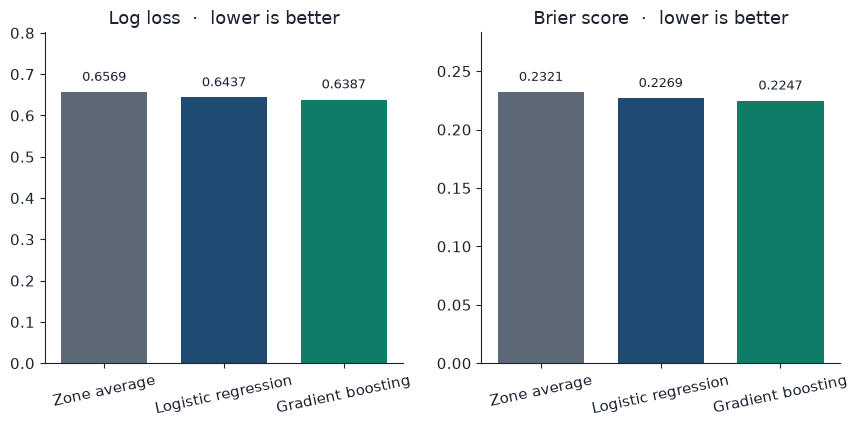

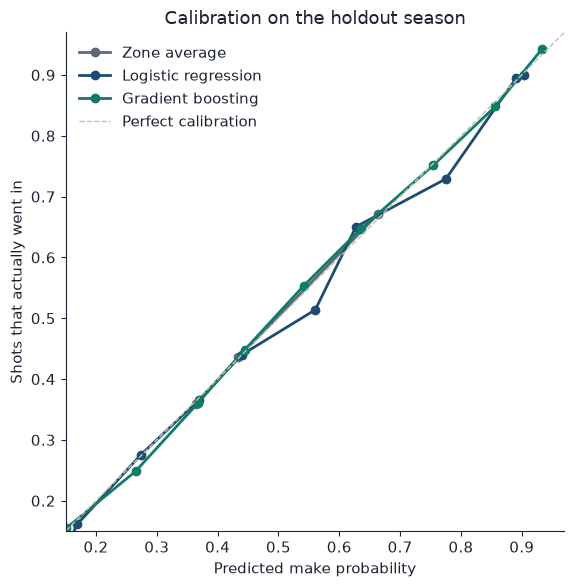

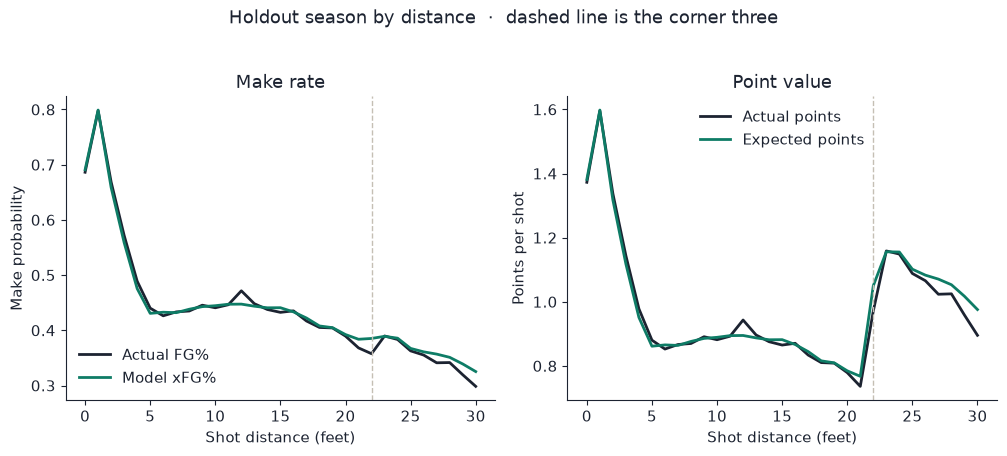

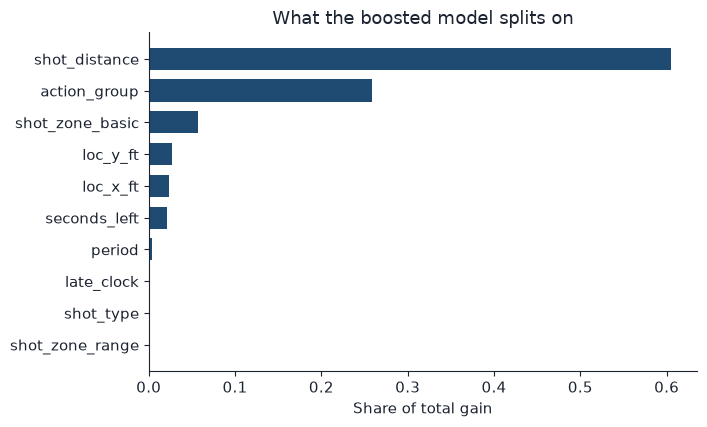

In [8]:
scored = trained["scored"]
fig = plot_model_comparison(trained["test"], FIGURES / "model_comparison.png")
display(fig)
plt.close(fig)

fig = plot_calibration(scored, FIGURES / "calibration.png")
display(fig)
plt.close(fig)

fig = plot_value_by_distance(scored, FIGURES / "value_by_distance.png")
display(fig)
plt.close(fig)

fig = plot_feature_importance(trained["importance"], FIGURES / "feature_importance.png")
display(fig)
plt.close(fig)


## From a probability to expected points

Expected points are the make probability times 2 or 3. A 40% three is worth 1.20. A 50% long two is worth 1.00. The distance chart is where that shows up: FG% drifts down as shots get longer, then points jump at the three-point line.

Points over expected are actual points minus expected points. Shot selection is average expected points versus the league. Those are different rankings, and they should be. The heat maps are the holdout model, not the raw make rate. Rim hexes include layups and dunks, so a high number there is the shot mix, not a promise about a contested jumper.


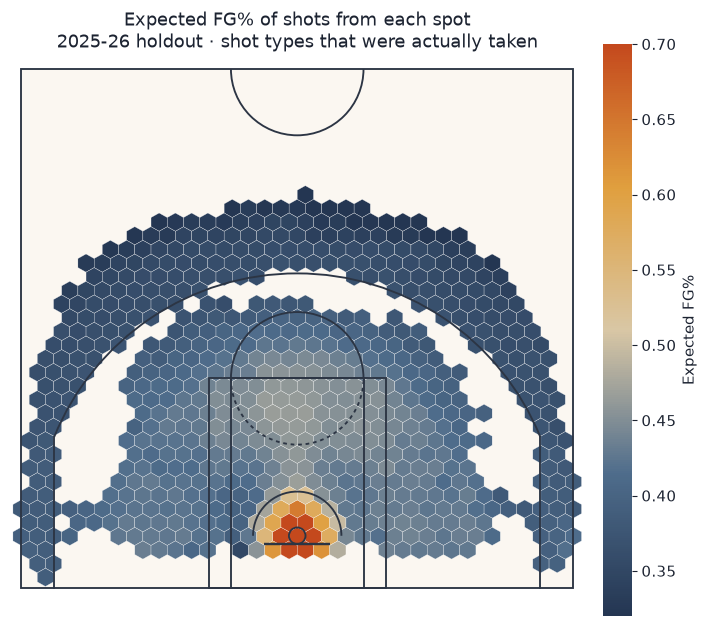

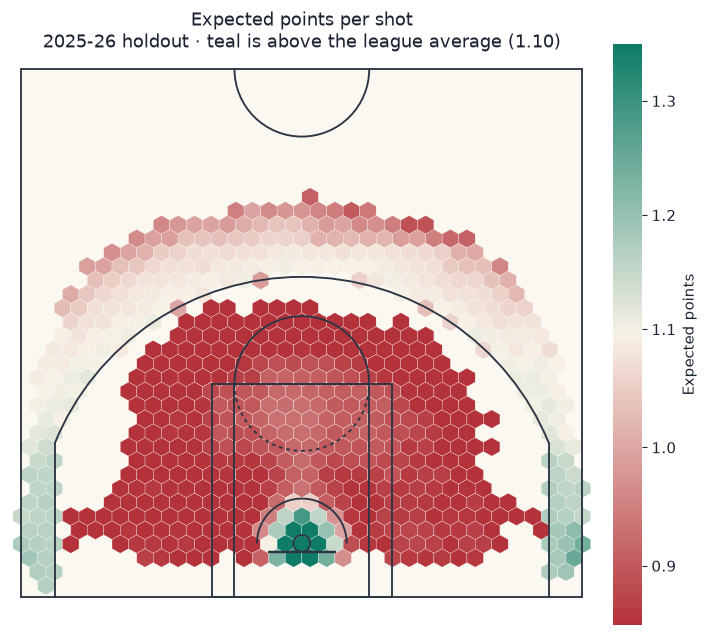

In [9]:
fig = plot_xfg_heatmap(scored, FIGURES / "xfg_heatmap.png")
display(fig)
plt.close(fig)

fig = plot_xpts_heatmap(scored, FIGURES / "xpts_heatmap.png")
display(fig)
plt.close(fig)


## Who beat the price, and who took the best shots

Counting is SQL on the holdout predictions. Shrinkage is Python. Shot-making averages are pulled toward the league with a prior strength estimated from the residuals (k, in shots). A player with n = k is halfway to the league. Players under 300 attempts stay in the file and off the leaderboard.

Whiskers on the bar charts are the standard error of the raw average, sigma / sqrt(n). Sigma is about 1.17 points. A 300-shot season still has a wide bar.


In [10]:
connection = build_database(shots, scored, db_path)
raw_players = player_aggregate(connection)
print("SQL aggregate, highest volume:")
display(raw_players.head(5))

boards = build_leaderboards(connection, scored)
connection.close()

making = boards["making_shrinkage"]
selection = boards["selection_shrinkage"]
print(f"Shot-making prior strength k = {making['k']:.0f} shots")
print(f"Shot-selection prior strength k = {selection['k']:.1f} shots")
print(f"Residual SD = {boards['sigma_residual']:.2f} points")
print(
    f"Holdout: FG% {boards['league']['fg_pct']:.1%}, "
    f"xFG% {boards['league']['xfg']:.1%}, "
    f"points/shot {boards['league']['points_per_shot']:.3f}, "
    f"xPTS/shot {boards['league']['xpts_per_shot']:.3f}"
)
print(f"Qualified players (300+ FGA): {boards['league']['qualified_players']} of {boards['league']['players']}")

qualified = boards["players"].loc[boards["players"]["qualified"]].copy()
show = [
    "player_name",
    "team_name",
    "fga",
    "fg_pct",
    "xfg",
    "selection_per_100_shrunk",
    "poe_per_100",
    "poe_per_100_shrunk",
    "poe_se_per_100",
    "poe_total",
]
print("Best shot-making, shrunk points over expected per 100:")
display(qualified.nlargest(8, "poe_per_100_shrunk")[show].round(3))
print("Toughest shot-making seasons:")
display(qualified.nsmallest(5, "poe_per_100_shrunk")[show].round(3))
print("Best shot diets:")
display(qualified.nlargest(5, "selection_per_100_shrunk")[show].round(3))
print("Hardest shot diets:")
display(qualified.nsmallest(5, "selection_per_100_shrunk")[show].round(3))


SQL aggregate, highest volume:


,player_id,player_name,fga,fgm,fg_pct,xfg,points,xpoints,xpts_per_shot,points_per_shot,poe_per_shot,n_teams,team_name,poe_total
0,1627759,Jaylen Brown,1543,736.0,0.476993,0.453270,1612.0,1544.513820,1.000981,1.044718,0.043737,1,Boston Celtics,67.486180
1,1630178,Tyrese Maxey,1500,693.0,0.462000,0.458692,1605.0,1588.689579,1.059126,1.070000,0.010874,1,Philadelphia 76ers,16.310421
2,1628973,Jalen Brunson,1475,689.0,0.467119,0.437410,1573.0,1483.207725,1.005565,1.066441,0.060876,1,New York Knicks,89.792275
3,1629029,Luka Dončić,1457,693.0,0.475635,0.416510,1640.0,1460.982059,1.002733,1.125601,0.122867,1,Los Angeles Lakers,179.017941
4,1628378,Donovan Mitchell,1403,678.0,0.483250,0.450833,1580.0,1486.751171,1.059694,1.126158,0.066464,1,Cleveland Cavaliers,93.248829


Shot-making prior strength k = 176 shots
Shot-selection prior strength k = 8.6 shots
Residual SD = 1.17 points
Holdout: FG% 47.1%, xFG% 47.2%, points/shot 1.091, xPTS/shot 1.095
Qualified players (300+ FGA): 284 of 582
Best shot-making, shrunk points over expected per 100:


,player_name,team_name,fga,fg_pct,xfg,selection_per_100_shrunk,poe_per_100,poe_per_100_shrunk,poe_se_per_100,poe_total
0,Luke Kennard,Atlanta Hawks,443,0.533,0.427,-3.572,27.053,19.242,5.561,119.847
1,Nikola Jokić,Denver Nuggets,1130,0.568,0.467,-6.858,20.728,17.878,3.482,234.225
2,Kevin Durant,Houston Rockets,1375,0.521,0.438,-9.949,18.138,16.032,3.157,249.402
3,Shai Gilgeous-Alexander,Oklahoma City Thunder,1321,0.553,0.474,-6.650,16.528,14.535,3.220,218.333
4,Cam Spencer,Memphis Grizzlies,556,0.473,0.406,-6.915,18.340,13.830,4.964,101.972
5,Luka Garza,Boston Celtics,357,0.577,0.486,0.626,20.626,13.677,6.195,73.636
6,Jakob Poeltl,Toronto Raptors,310,0.700,0.594,9.088,21.116,13.317,6.648,65.459
7,Deandre Ayton,Los Angeles Lakers,601,0.671,0.585,7.324,17.137,13.160,4.774,102.991


Toughest shot-making seasons:


,player_name,team_name,fga,fg_pct,xfg,selection_per_100_shrunk,poe_per_100,poe_per_100_shrunk,poe_se_per_100,poe_total
283,Nae'Qwan Tomlin,Cleveland Cavaliers,314,0.478,0.574,18.684,-24.598,-15.913,6.605,-77.239
282,Ben Saraf,Brooklyn Nets,303,0.396,0.491,-0.535,-23.516,-15.029,6.724,-71.255
281,Ronald Holland II,Detroit Pistons,544,0.432,0.503,4.664,-18.694,-14.226,5.018,-101.693
280,Nikola Jović,Miami Heat,314,0.366,0.448,-0.356,-21.600,-13.992,6.605,-67.824
279,Herbert Jones,New Orleans Pelicans,478,0.383,0.460,2.689,-18.977,-13.983,5.354,-90.711


Best shot diets:


,player_name,team_name,fga,fg_pct,xfg,selection_per_100_shrunk,poe_per_100,poe_per_100_shrunk,poe_se_per_100,poe_total
215,Rudy Gobert,Minnesota Timberwolves,491,0.682,0.712,32.692,-6.351,-4.786,5.282,-31.183
164,Daniel Gafford,Dallas Mavericks,316,0.655,0.665,22.903,-2.056,-1.470,6.584,-6.497
226,Collin Murray-Boyles,Toronto Raptors,342,0.579,0.617,18.905,-8.163,-5.532,6.329,-27.918
283,Nae'Qwan Tomlin,Cleveland Cavaliers,314,0.478,0.574,18.684,-24.598,-15.913,6.605,-77.239
157,Moussa Diabaté,Charlotte Hornets,363,0.631,0.639,18.029,-1.552,-1.182,6.143,-5.635


Hardest shot diets:


,player_name,team_name,fga,fg_pct,xfg,selection_per_100_shrunk,poe_per_100,poe_per_100_shrunk,poe_se_per_100,poe_total
22,DeMar DeRozan,Sacramento Kings,1005,0.497,0.441,-16.034,10.606,8.963,3.692,106.592
19,T.J. McConnell,Indiana Pacers,450,0.538,0.464,-12.354,14.155,10.057,5.518,63.696
172,Ryan Nembhard,Dallas Mavericks,390,0.415,0.426,-11.547,-2.359,-1.756,5.927,-9.202
160,Khris Middleton,Washington Wizards,540,0.420,0.426,-11.361,-1.523,-1.251,5.037,-8.223
2,Kevin Durant,Houston Rockets,1375,0.521,0.438,-9.949,18.138,16.032,3.157,249.402


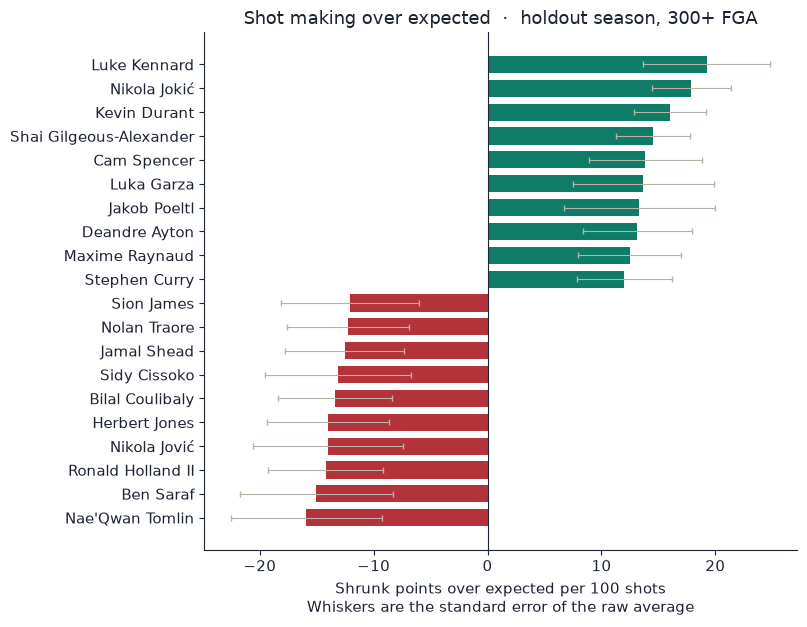

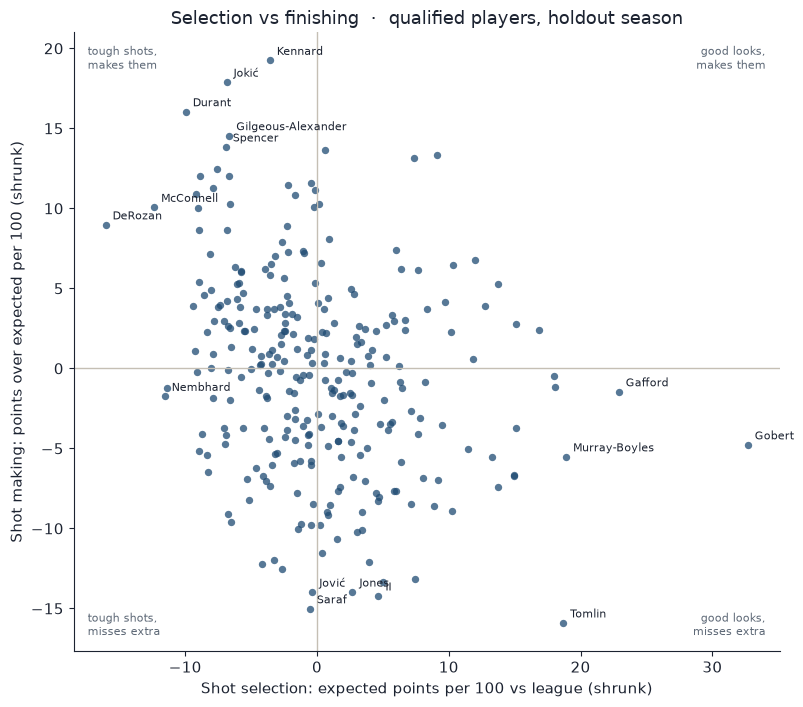

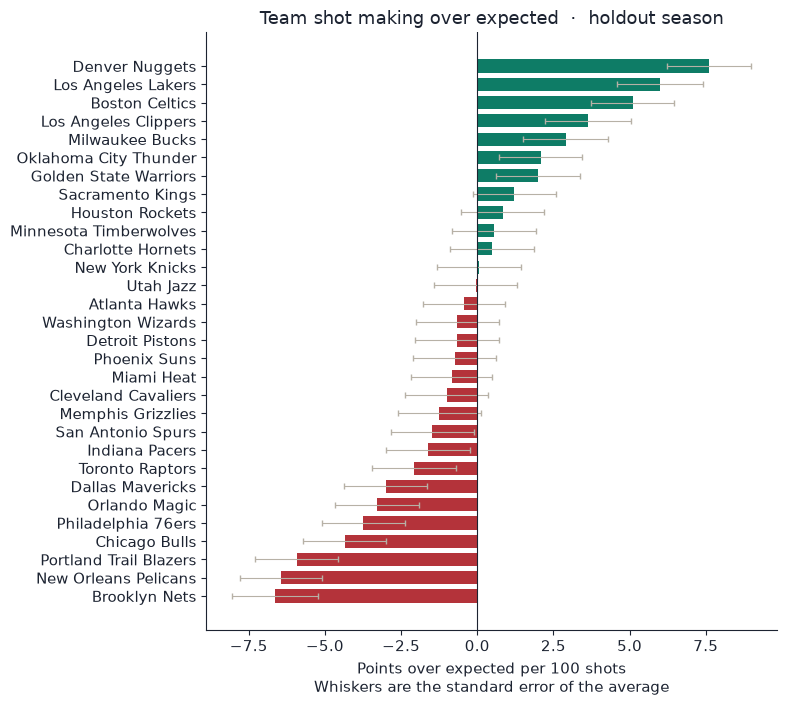

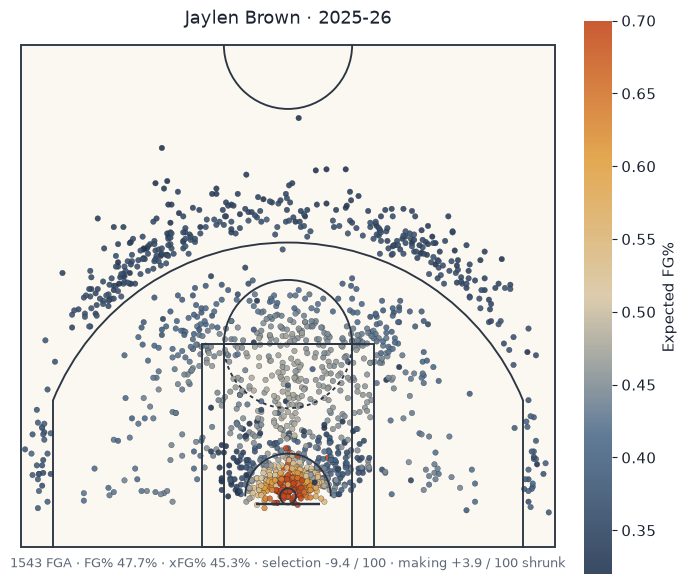

1543 FGA · FG% 47.7% · xFG% 45.3% · selection -9.4 / 100 · making +3.9 / 100 shrunk


In [11]:
fig = plot_player_making(boards["players"], FIGURES / "player_shot_making.png")
display(fig)
plt.close(fig)

fig = plot_selection_vs_making(boards["players"], FIGURES / "selection_vs_making.png")
display(fig)
plt.close(fig)

fig = plot_team_making(boards["teams"], FIGURES / "team_shot_making.png")
display(fig)
plt.close(fig)

example = qualified.sort_values("fga", ascending=False).iloc[0]
player_shots = scored.loc[scored["player_id"] == example["player_id"]]
subtitle = (
    f"{int(example['fga'])} FGA · FG% {example['fg_pct']:.1%} · xFG% {example['xfg']:.1%} · "
    f"selection {example['selection_per_100_shrunk']:+.1f} / 100 · "
    f"making {example['poe_per_100_shrunk']:+.1f} / 100 shrunk"
)
fig = plot_player_chart(
    player_shots,
    FIGURES / "example_player_chart.png",
    title=f"{example['player_name']} · 2025-26",
    subtitle=subtitle,
)
display(fig)
plt.close(fig)
print(subtitle)


## What this does not know

There is no defender distance and no shot clock, only the game clock. A wide-open three and a contested three at the same spot get the same features, except for whatever the action label and the clock imply.

Dunks are in the model, so a player who only dunks looks like a good selector, not an extra shot-maker. That is a choice. Gobert-type shot diets and Durant-type shot making are the two sides of it.

One season of residuals is noisy. The standard errors and the shrinkage are there so a 300-shot hot streak cannot pretend to be a career. Team ranks in the middle of the board are inside the noise. The ends of the board, Denver on one side and Brooklyn, New Orleans, and Portland on the other in this holdout, are not.

The score columns in the raw feed were not used. They are missing on misses and they mix in free throws on makes. Using them as the pre-shot score would have been leakage or a bad feature. Leaving them out is the conservative choice.
